In [1]:
!pip install faiss-cpu

Exact NN (Flat) indices: [[895 451 375]] distances: [[0.04164944 0.04808223 0.05523108]]
IVF+PQ indices: [[182 172 848]] distances: [[0.08804266 0.09089994 0.11803695]]
Waktu Exact: 0.0017981529235839844
Waktu IVF+PQ: 0.0017082691192626953


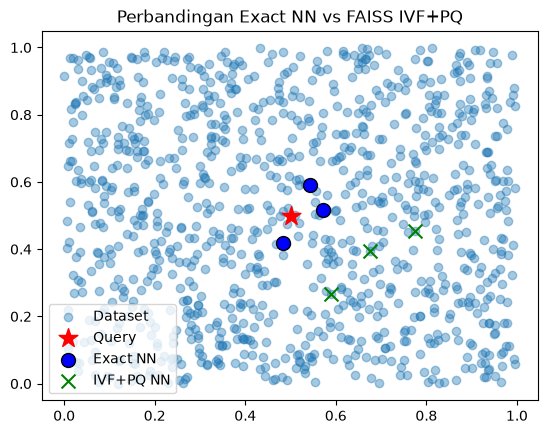

In [2]:
import numpy as np
import faiss
import matplotlib.pyplot as plt
import time

np.random.seed(42)
X = np.random.rand(1000, 5).astype('float32')
query = np.array([[0.5, 0.5, 0.5, 0.5, 0.5]], dtype='float32')

index_flat = faiss.IndexFlatL2(5)
index_flat.add(X)

start = time.time()
D_flat, I_flat = index_flat.search(query, 3)
end = time.time()
time_flat = end - start

nlist = 10
m = 5
quantizer = faiss.IndexFlatL2(5)
index_ivfpq = faiss.IndexIVFPQ(quantizer, 5, nlist, m, 8)
index_ivfpq.train(X)
index_ivfpq.add(X)

start = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
end = time.time()
time_ivfpq = end - start

print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
print("Waktu Exact:", time_flat)
print("Waktu IVF+PQ:", time_ivfpq)

plt.scatter(X[:,0], X[:,1], alpha=0.4, label="Dataset")
plt.scatter(query[:,0], query[:,1], c='red', marker='*', s=200, label="Query")

plt.scatter(X[I_flat[0],0], X[I_flat[0],1], c='blue', s=100, edgecolor='k', label="Exact NN")

plt.scatter(X[I_ivfpq[0],0], X[I_ivfpq[0],1], c='green', marker='x', s=100, label="IVF+PQ NN")

plt.legend()
plt.title("Perbandingan Exact NN vs FAISS IVF+PQ")
plt.show()

In [3]:
np.random.seed(42)
X = np.random.rand(1000, 5).astype("float32")
query = np.array([[0.5] * 5], dtype="float32")

# Manhattan (L1)
index_l1 = faiss.IndexFlat(5, faiss.METRIC_L1)
index_l1.add(X)

start = time.perf_counter()
D_l1, I_l1 = index_l1.search(query, 3)
time_l1 = time.perf_counter() - start

print("Manhattan indices:", I_l1)
print("Manhattan distances:", D_l1)
print("Waktu Manhattan:", time_l1)

Manhattan indices: [[451 375 895]]
Manhattan distances: [[0.4072487  0.40841904 0.40937075]]
Waktu Manhattan: 0.0008566999999857217


In [4]:
np.random.seed(42)
X = np.random.rand(1000, 5).astype("float32")
query = np.array([[0.5] * 5], dtype="float32")

# Normalisasi agar Inner Product menjadi Cosine Similarity
faiss.normalize_L2(X)
faiss.normalize_L2(query)

index_cosine = faiss.IndexFlatIP(5)
index_cosine.add(X)

start = time.perf_counter()
D_cosine, I_cosine = index_cosine.search(query, 3)
time_cosine = time.perf_counter() - start

print("Cosine indices:", I_cosine)
print("Cosine similarity scores:", D_cosine)
print("Waktu Cosine:", time_cosine)

Cosine indices: [[248 386 229]]
Cosine similarity scores: [[0.99853027 0.99741614 0.99504924]]
Waktu Cosine: 0.0003713999999490625


In [5]:
import pandas as pd

hasil = [
    {
        "Jumlah Data": 1000,
        "Dimensi": "2D",
        "Metrik": "L2",
        "Waktu Exact (s)": 0.000416,
        "Waktu IVF+PQ (s)": 0.000194
    },
    {
        "Jumlah Data": 1000,
        "Dimensi": "5D",
        "Metrik": "L2",
        "Waktu Exact (s)": 0.000301,
        "Waktu IVF+PQ (s)": 0.000305
    },
    {
        "Jumlah Data": 1_000_000,
        "Dimensi": "2D",
        "Metrik": "L2",
        "Waktu Exact (s)": 0.003431,
        "Waktu IVF+PQ (s)": 0.006119
    },
    {
        "Jumlah Data": 1_000_000,
        "Dimensi": "5D",
        "Metrik": "L2",
        "Waktu Exact (s)": 0.003525,
        "Waktu IVF+PQ (s)": 0.001184
    }
]

df = pd.DataFrame(hasil)
display(df)

,Jumlah Data,Dimensi,Metrik,Waktu Exact (s),Waktu IVF+PQ (s)
0,1000,2D,L2,0.000416,0.000194
1,1000,5D,L2,0.000301,0.000305
2,1000000,2D,L2,0.003431,0.006119
3,1000000,5D,L2,0.003525,0.001184
